<a href="https://colab.research.google.com/github/Lois-coder1/Renewables/blob/main/Copy_of_predicting_solar_generation_potential.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total rows = 40183
Total columns = 12
        date  ALLSKY_SFC_SW_DWN  CLRSKY_SFC_SW_DWN    T2M   RH2M  PRECTOTCORR  \
0 2015-01-01             5.7622             5.7854  25.23  68.26          0.0   
1 2015-01-02             6.0350             6.0478  26.16  73.23          0.0   
2 2015-01-03             5.3186             5.3717  25.66  78.71          0.0   
3 2015-01-04             5.8462             5.8870  24.11  63.66          0.0   
4 2015-01-05             5.1638             5.2082  23.40  59.45          0.0   
5 2015-01-06             5.5433             5.5577  22.66  62.57          0.0   
6 2015-01-07             4.4465             4.6061  23.53  61.92          0.0   
7 2015-01-08             5.1504             5.3074  24.06  61.78          0.0   
8 2015-01-09             5.1787             5.2855  23.09  67.38          0.0   
9 2015-01-10             5.8889             5.9321  21.71  62.88          0.0   

   CLOUD_AMT   city        zone  population     lat     lon  
0       

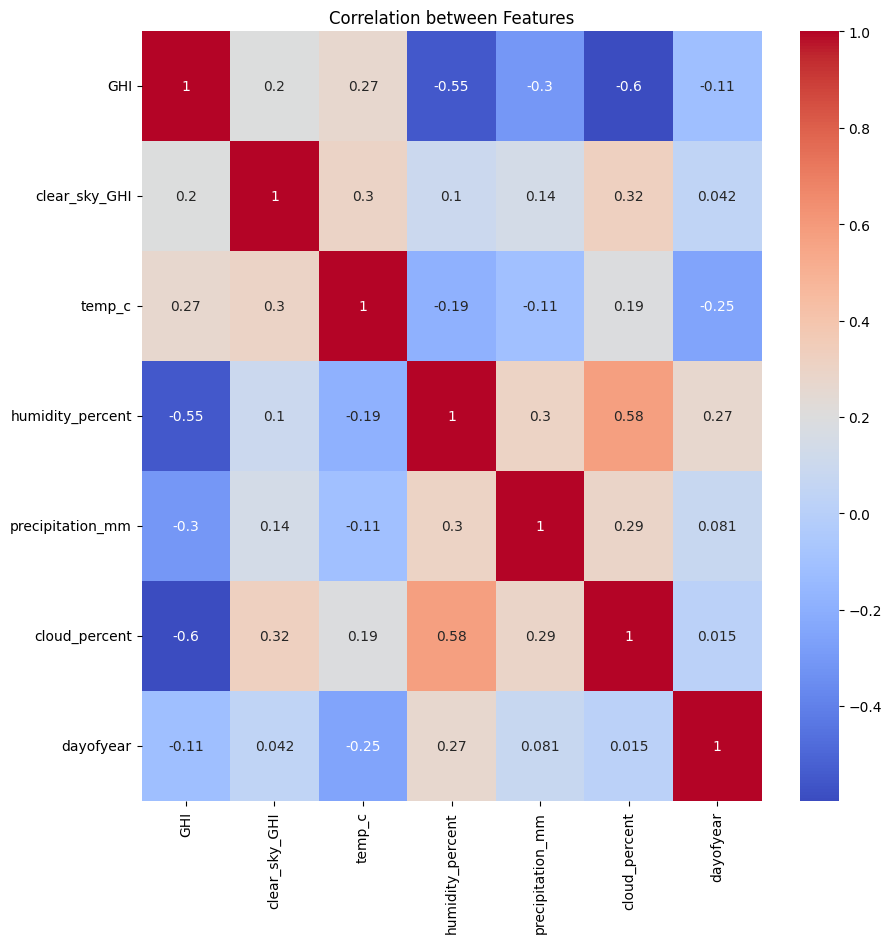

Linear Regression  RMSE: 0.6730  R²: 0.6509
Random Forest  RMSE: 0.5548  R²: 0.7627
Gradient Boosting  RMSE: 0.5567  R²: 0.7611
Best model: Random Forest


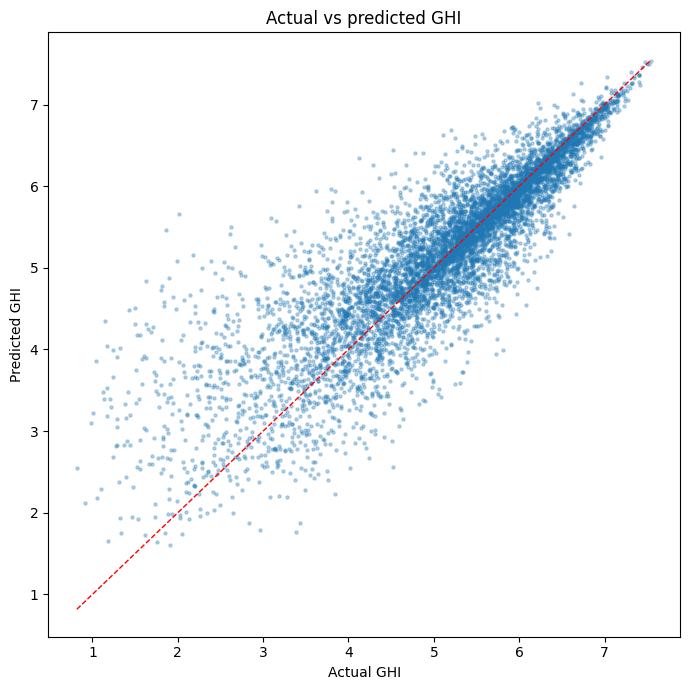

CV R²: [0.496 0.611 0.681 0.697 0.717]  mean: 0.640
   city  pop_millions  demand_kwh_year
   Kano         16.25     6177600000.0
  Lagos         15.77     5995123200.0
 Rivers          7.23     2748556800.0
  Benue          6.69     2543270400.0
Plateau          6.69     2543270400.0
  Borno          6.65     2528064000.0
 Sokoto          6.16     2341785600.0
    Edo          5.53     2102284800.0
  Enugu          5.40     2052864000.0
  Abuja          4.80     1824768000.0
  Kwara          4.26     1619481600.0


city,zone,annual_kwh_m2,m2_needed_per_1000_people,total_m2_needed_per_state
Sokoto,North West,295.994480,1284.348275,7911585.374215
Borno,North East,293.952758,1293.269038,8600239.102595
Kano,North West,290.030805,1310.757317,21299806.401250
Plateau,North Central,263.541164,1442.507102,9650372.510895
Kwara,North Central,260.028673,1461.992617,6228088.546756
Abuja,North Central,258.856213,1468.614549,7049349.836294
Benue,North Central,252.464779,1505.794199,10073763.190382
Enugu,South East,237.745596,1599.020156,8634708.841577
Lagos,South West,230.389746,1650.073439,26021658.126964
Edo,South South,230.269776,1650.933120,9129660.151090


City,Geographical Zone,Population (Millions),Annual Solar Gen (kWh/m²),Annual Demand (kWh),"Solar Panel Area Needed per 1,000 People (m²)",State Solar Panel Area Needed (m²)
Sokoto,North West,6.160000,295.994480,2341785600.000000,1284.348275,7911585.374215
Borno,North East,6.650000,293.952758,2528064000.000000,1293.269038,8600239.102595
Kano,North West,16.250000,290.030805,6177600000.000000,1310.757317,21299806.401250
Plateau,North Central,6.690000,263.541164,2543270400.000000,1442.507102,9650372.510895
Kwara,North Central,4.260000,260.028673,1619481600.000000,1461.992617,6228088.546756
Abuja,North Central,4.800000,258.856213,1824768000.000000,1468.614549,7049349.836294
Benue,North Central,6.690000,252.464779,2543270400.000000,1505.794199,10073763.190382
Enugu,South East,5.400000,237.745596,2052864000.000000,1599.020156,8634708.841577
Lagos,South West,15.770000,230.389746,5995123200.000000,1650.073439,26021658.126964
Edo,South South,5.530000,230.269776,2102284800.000000,1650.933120,9129660.151090


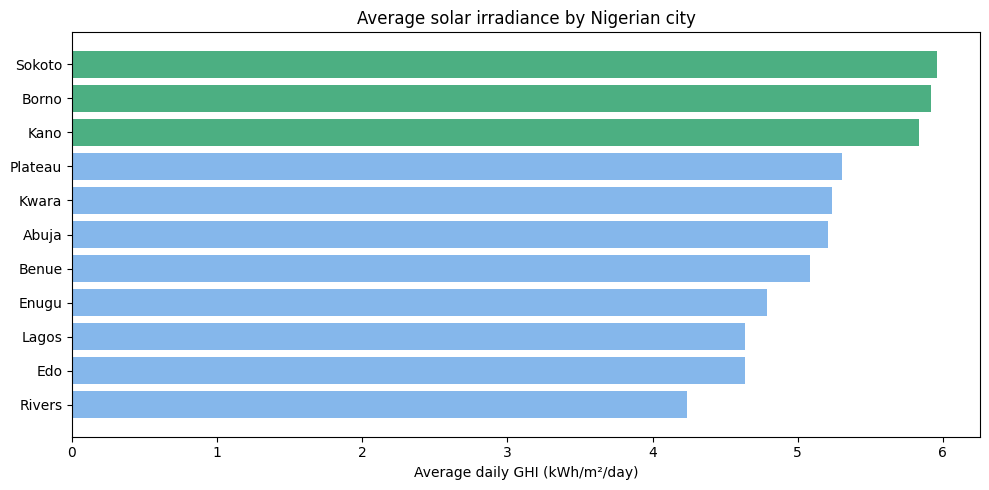

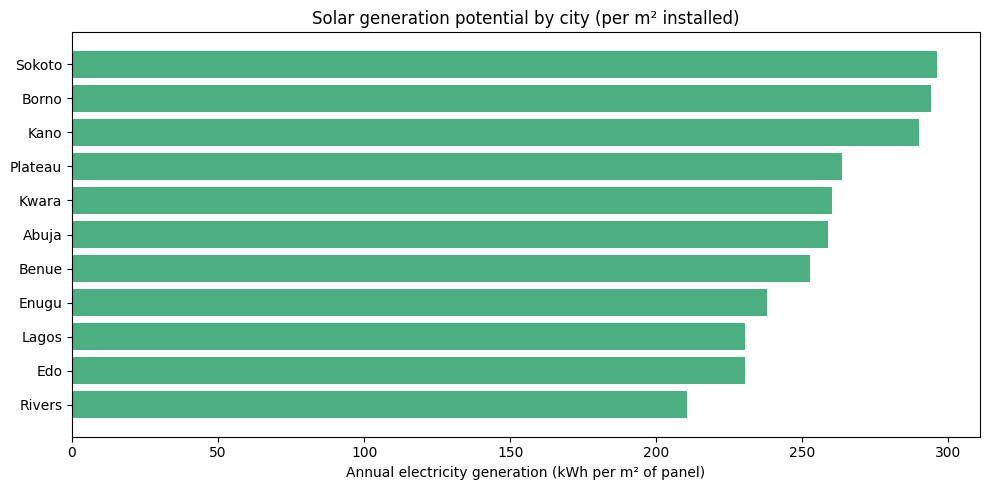

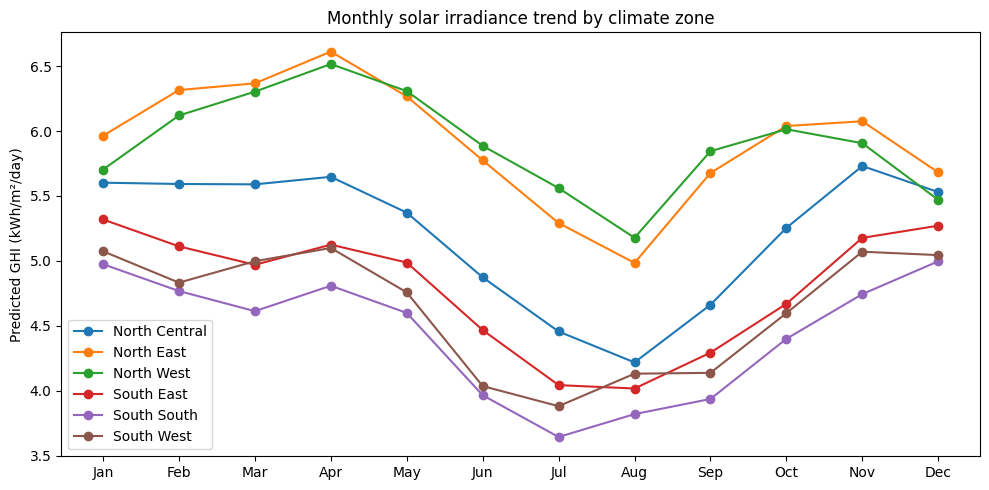

In [ ]:

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder


#all states used in model
# population in millions
states = {
    'Lagos':         {'lat': 6.4561, 'lon': 3.3936,  'zone': 'South West', 'population': 15.77},
    'Rivers': {'lat': 4.8396, 'lon': 6.9112,  'zone': 'South South', 'population':  7.23},
    'Edo':    {'lat': 6.5000,  'lon': 6.0000,  'zone': 'South South', 'population':  5.53},
    'Enugu':         {'lat': 6.5000,  'lon': 7.5000,  'zone': 'South East', 'population':  5.40},
    'Kwara':        {'lat': 9.0000,  'lon': 4.5000,  'zone': 'North Central', 'population': 4.26},
    'Abuja':         {'lat': 8.8333,  'lon': 7.1667,  'zone': 'North Central', 'population': 4.80},
    'Benue':       {'lat': 7.2800,  'lon': 8.8900,  'zone': 'North Central', 'population': 6.69},
    'Plateau':           {'lat': 9.1667,  'lon': 8.7500,  'zone': 'North Central', 'population': 5.4},
    'Kano':          {'lat': 11.5000, 'lon': 8.500,  'zone': 'North West', 'population':  16.25},
    'Sokoto':        {'lat': 13.0830, 'lon': 5.2500,  'zone': 'North West', 'population':  6.16},
    'Borno':     {'lat': 11.8311, 'lon': 13.1510, 'zone': 'North East', 'population':  6.65},
}

url = "https://power.larc.nasa.gov/api/temporal/daily/point"
def citydata(city_name, lat, lon):
  params = {
    "parameters": "ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,RH2M,PRECTOTCORR,CLOUD_AMT",
    "community":  "RE",
    "longitude":  lon,
    "latitude":   lat,
    "start":      "20150101",
    "end":        "20241231",
    "format":     "JSON"
  }

  response = requests.get(url, params=params, timeout=300)
  data = response.json()["properties"]["parameter"]

  df = pd.DataFrame(data)
  df.index = pd.to_datetime(df.index, format="%Y%m%d")
  df.index.name = "date"
  df["city"] = city_name
  return df.reset_index()

all_dfs = []
for name, info in states.items():
  df = citydata(name, info["lat"], info["lon"])
  df ['zone'] = info['zone']
  df ['population'] = info['population']
  df['lat'] = info['lat']
  df['lon'] = info['lon']
  all_dfs.append(df)
final_df = pd.concat(all_dfs, ignore_index = True)
print(f"Total rows = {len(final_df)}")
print(f"Total columns = {len(final_df.columns)}")
print(final_df.head(10))

dataset = final_df.copy()
dataset = dataset.dropna().rename(columns= {
    'ALLSKY_SFC_SW_DWN': 'GHI',
    'CLRSKY_SFC_SW_DWN': 'clear_sky_GHI',
    'T2M': 'temp_c',
    'RH2M': 'humidity_percent',
    'PRECTOTCORR': 'precipitation_mm',
    'CLOUD_AMT': 'cloud_percent'
})

dataset.duplicated().sum()

#data cleaning
dataset.replace(-999, np.nan, inplace=True)
print(dataset[['GHI', 'clear_sky_GHI', 'temp_c', 'humidity_percent', 'precipitation_mm', 'cloud_percent']].isnull().sum())

dataset['month'] = dataset['date'].dt.month
dataset['dayofyear'] = dataset['date'].dt.dayofyear
def seasons(row):
  d = row['date'].month
  z = row['zone']
  if 'North' in z:
    return 'dry' if d in [10,11,12,1,2,3,4] else 'wet'
  else:
    return 'dry' if d in [12,1,2,3] else 'wet'

dataset['season'] = dataset.apply(seasons, axis = 1)

# temperature penalty is already included in performance ratio of solar panels in Nigeria

train_dataset, test_dataset = train_test_split(dataset, test_size=0.2, random_state=67)

le_season = LabelEncoder()

# Fit label encoders on the full dataset to avoid label issues
dataset["seasonenc"] = le_season.fit_transform(dataset["season"])

train_dataset = train_dataset.copy()
test_dataset = test_dataset.copy()

train_dataset = dataset[dataset['date'] < '2023-01-01'].copy()
test_dataset  = dataset[dataset['date'] >= '2023-01-01'].copy()


FEATURES = [
    'month', 'dayofyear', 'temp_c', 'humidity_percent', 'precipitation_mm', 'cloud_percent',
    'clear_sky_GHI', 'lat', 'lon', 'seasonenc'
]

corr_cols = ['GHI', 'clear_sky_GHI', 'temp_c', 'humidity_percent',
             'precipitation_mm', 'cloud_percent', 'dayofyear']

matrix = dataset[corr_cols].corr()
plt.figure(figsize = (10,10))
sns.heatmap(matrix, annot = True, cmap = 'coolwarm')
plt.title("Correlation between Features")
plt.show()

TARGET = 'GHI'

# Separate feature matrix and target vectors directly from separate splits
x_train = train_dataset[FEATURES]
y_train = train_dataset[TARGET]

x_test = test_dataset[FEATURES]
y_test = test_dataset[TARGET]

models = {
    "Linear Regression":     LinearRegression(),
    "Random Forest":         RandomForestRegressor(n_estimators=100, random_state=67, n_jobs=-1),
    "Gradient Boosting":     GradientBoostingRegressor(n_estimators=100, random_state=67),
}

results = {}
for name, model in models.items():
    model.fit(x_train, y_train)
    predicted = model.predict(x_test)
    rmse = np.sqrt(mean_squared_error(y_test, predicted))
    r2  = r2_score(y_test, predicted)
    results[name] = {"model": model, "rmse": rmse, "r2": r2, "predicted": predicted}
    print(f"{name}  RMSE: {rmse:.4f}  R²: {r2:.4f}")


best_model_name = max(results, key=lambda k: results[k]["r2"])
best_model = results[best_model_name]["model"]
print(f"Best model: {best_model_name}")


preds = results[best_model_name]["predicted"]

#visualisation 1
plt.figure(figsize=(7,7))
plt.scatter(y_test, preds, alpha=0.3, s=5)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--', linewidth=1)
plt.xlabel("Actual GHI")
plt.ylabel("Predicted GHI")
plt.title("Actual vs predicted GHI")
plt.tight_layout()
plt.show()


#r2 cross-validation
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
cv_scores = cross_val_score(best_model, x_train, y_train,
                            cv=TimeSeriesSplit(n_splits=5), scoring='r2')
print(f"CV R²: {cv_scores.round(3)}  mean: {cv_scores.mean():.3f}")


performance_ratio = 0.8
panel_efficiency = 0.17

dataset['predicted_irradiance'] = best_model.predict(dataset[FEATURES])
dataset["daily_gen_kwh_m2"] = dataset["predicted_irradiance"] * panel_efficiency * performance_ratio

# Use dataset instead of df to perform the aggregation over all states over 10 years
total_10_yrs = dataset.groupby("city").agg(
    annual_kwh_m2 = ("daily_gen_kwh_m2", "sum"),
    avg_GHI       = ("predicted_irradiance", "mean"),
    avg_temp      = ("temp_c", "mean"),
    zone          = ("zone", "first"),
    pop_millions  = ("population", "first")
).reset_index()

# Create annual_solar DataFrame and divide the 10-year totals by 10 to get annual values
annual_solar = total_10_yrs.copy()
annual_solar["annual_kwh_m2"] = annual_solar["annual_kwh_m2"] / 10

avg_kwh_required_per_person_annually = 380.16

#this figure is the Sub-Saharan average consumption
#Nigeria residents quote a 164kWh/annum figure, which is due to the massive power outages and restrictions
#the Sub-Saharan figure is also well below the worldwide average


annual_solar["demand_kwh_year"] = annual_solar["pop_millions"] * 1_000_000 * avg_kwh_required_per_person_annually

# Neatly print the annual energy demand for each city
print(annual_solar[["city", "pop_millions", "demand_kwh_year"]].sort_values("demand_kwh_year", ascending=False).to_string(index=False))

demand_per_1000_people = 1000 * avg_kwh_required_per_person_annually # 380,160 kWh/year

annual_solar["m2_needed_per_1000_people"] = demand_per_1000_people / annual_solar["annual_kwh_m2"]

# Calculate Total Solar Panel Area Needed (m²) for the total population of each city
# Population in millions * 1,000,000 gives total population
# Since m2_needed_per_1000_people is for 1000 people, we multiply by (population_total / 1000)

annual_solar["total_m2_needed"] = annual_solar["m2_needed_per_1000_people"] * (annual_solar["pop_millions"] * 1000000 / 1000)
annual_solar["total_km2_needed"] = annual_solar["total_m2_needed"] / 1000000


annual_solar["total_m2_needed_per_state"] = annual_solar["m2_needed_per_1000_people"]*(annual_solar["pop_millions"]*1000)

#Table of Results
display(annual_solar[["city", "zone", "annual_kwh_m2", "m2_needed_per_1000_people", "total_m2_needed_per_state"]].sort_values("m2_needed_per_1000_people").style.hide(axis="index"))

#Summary Table
summary_df = annual_solar[["city", "zone", "pop_millions", "annual_kwh_m2", "demand_kwh_year", "m2_needed_per_1000_people", "total_m2_needed_per_state"]].copy()
summary_df.columns = [
    "City",
    "Geographical Zone",
    "Population (Millions)",
    "Annual Solar Gen (kWh/m²)",
    "Annual Demand (kWh)",
    "Solar Panel Area Needed per 1,000 People (m²)",
    "State Solar Panel Area Needed (m²)"
]

display(summary_df.sort_values("Annual Solar Gen (kWh/m²)", ascending=False).style.hide(axis="index"))


#per city solar irradiance
fig, ax = plt.subplots(figsize=(10, 5))
sorted_df = annual_solar.sort_values("avg_GHI", ascending=True)
colors = ["#4CAF82" if z in ["North East","North West"] else "#85B7EB"
          for z in sorted_df["zone"]]
ax.barh(sorted_df["city"], sorted_df["avg_GHI"], color=colors)
ax.set_xlabel("Average daily GHI (kWh/m²/day)")
ax.set_title("Average solar irradiance by Nigerian city")
plt.tight_layout()
plt.savefig("chart1_ghi_by_city.png", dpi=150)
plt.show()



#annual kWh potential
fig, ax = plt.subplots(figsize=(10, 5))
sorted_df2 = annual_solar.sort_values("annual_kwh_m2", ascending=True)
ax.barh(sorted_df2["city"], sorted_df2["annual_kwh_m2"], color="#4CAF82")
ax.set_xlabel("Annual electricity generation (kWh per m² of panel)")
ax.set_title("Solar generation potential by city (per m² installed)")
plt.tight_layout()
plt.savefig("chart2_generation_potential.png", dpi=150)
plt.show()



#monthly view of solar irradiance
monthly = dataset.groupby(["zone","month"])["predicted_irradiance"].mean().reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
for zone in monthly["zone"].unique():
    zone_data = monthly[monthly["zone"] == zone]
    ax.plot(zone_data["month"], zone_data["predicted_irradiance"], marker="o", label=zone)
ax.set_xticks(range(1,13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Predicted GHI (kWh/m²/day)")
ax.set_title("Monthly solar irradiance trend by climate zone")
ax.legend()
plt.tight_layout()
plt.savefig("chart3_monthly_trend.png", dpi=150)
plt.show()

In [ ]:
#import all the datasets
#pull all the features from NASA POWER API
# Encode them
#run random forest, linear regression, gradient boosting
#compare results
#do the whole convert to power
#create table